# Q13 — Ant Colony Optimisation for Shortest-Path Finding

## Problem setup
We want the lowest-cost path from start node **S** to destination **G** in a weighted graph. Each edge has a travel cost. Ant Colony Optimisation (ACO) imitates how ants reinforce useful routes: ants probabilistically choose their next node using pheromone and inverse edge cost, trails evaporate over time, and successful paths deposit more pheromone. ACO is a heuristic; we can check the answer on this small graph against a standard shortest-path calculation.

## 1. Build the graph and inspect its edges

The graph is undirected. Each listed edge can be traversed in either direction at the same cost. We print the edge list and adjacency table before running the colony.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import heapq

random.seed(21)
nodes = ['S','A','B','C','D','E','G']
edges = [('S','A',2),('S','B',4),('A','C',2),('A','D',5),('B','D',1),('B','E',3),('C','G',3),('D','G',4),('D','C',1),('E','G',2),('C','E',2)]
adj = {node: [] for node in nodes}
for u, v, cost in edges:
    adj[u].append((v, cost)); adj[v].append((u, cost))
print(f"Nodes: {len(nodes)}; undirected edges: {len(edges)}")
print("Edge list (node -- node : cost)")
for u, v, cost in edges:
    print(f"{u} -- {v} : {cost}")
print("\nAdjacency list")
for node in nodes:
    print(f"{node}: " + ", ".join(f"{v} (cost {w})" for v,w in adj[node]))

Nodes: 7; undirected edges: 11
Edge list (node -- node : cost)
S -- A : 2
S -- B : 4
A -- C : 2
A -- D : 5
B -- D : 1
B -- E : 3
C -- G : 3
D -- G : 4
D -- C : 1
E -- G : 2
C -- E : 2

Adjacency list
S: A (cost 2), B (cost 4)
A: S (cost 2), C (cost 2), D (cost 5)
B: S (cost 4), D (cost 1), E (cost 3)
C: A (cost 2), G (cost 3), D (cost 1), E (cost 2)
D: A (cost 5), B (cost 1), G (cost 4), C (cost 1)
E: B (cost 3), G (cost 2), C (cost 2)
G: C (cost 3), D (cost 4), E (cost 2)


## 2. Transition probabilities and pheromone

For a candidate neighbour \(v\), the selection weight is \(\tau_{uv}^{\alpha}(1/d_{uv})^{\beta}\). The weights are normalised into probabilities. A path avoids revisiting nodes, which prevents loops. Each successful ant deposits \(Q/L\) on every edge in its path. At the end of an iteration, old pheromone is multiplied by \((1-\rho)\).

In [2]:
alpha, beta = 1.0, 2.0
rho, Q = 0.25, 10.0
ants_per_iteration, iterations = 25, 80
pheromone = {(u,v): 1.0 for u,v,w in edges for u,v in [(u,v),(v,u)]}

def transition_probabilities(current, options):
    weights = [pheromone[(current,v)]**alpha * (1.0/cost)**beta for v,cost in options]
    total = sum(weights)
    return [weight/total for weight in weights]

print(f"alpha={alpha}, beta={beta}, evaporation rho={rho}, deposit Q={Q}")
print(f"Ants per iteration={ants_per_iteration}; iterations={iterations}")
print("\nExample initial choices from S")
options = adj['S']
for (node,cost), probability in zip(options, transition_probabilities('S', options)):
    print(f"S -> {node}: cost={cost}, pheromone={pheromone[('S',node)]:.2f}, probability={probability:.4f}")

alpha=1.0, beta=2.0, evaporation rho=0.25, deposit Q=10.0
Ants per iteration=25; iterations=80

Example initial choices from S
S -> A: cost=2, pheromone=1.00, probability=0.8000
S -> B: cost=4, pheromone=1.00, probability=0.2000


## 3. Run the colony and print progress

Each ant builds a path from S until it reaches G or gets stuck. Successful routes contribute pheromone. We retain the best path seen across the entire run and print selected iterations so that progress is readable.

In [3]:
def construct_path():
    path, visited, current, cost = ['S'], {'S'}, 'S', 0
    for _ in range(len(nodes)-1):
        if current == 'G':
            break
        options = [(v,w) for v,w in adj[current] if v not in visited]
        if not options:
            return path, None
        probabilities = transition_probabilities(current, options)
        nxt, edge_cost = random.choices(options, weights=probabilities, k=1)[0]
        path.append(nxt); visited.add(nxt); cost += edge_cost; current = nxt
    return (path, cost) if current == 'G' else (path, None)

best_path, best_cost = None, float('inf')
best_history, feasible_by_iteration = [], []
progress = {}
for iteration in range(iterations):
    successful = []
    for _ in range(ants_per_iteration):
        path, cost = construct_path()
        if cost is not None:
            successful.append((path, cost))
            if cost < best_cost:
                best_path, best_cost = path[:], cost
    feasible_by_iteration.append(len(successful))
    for edge in list(pheromone):
        pheromone[edge] *= (1-rho)
    for path, cost in successful:
        deposit = Q / cost
        for u, v in zip(path[:-1], path[1:]):
            pheromone[(u,v)] += deposit
            pheromone[(v,u)] += deposit
    best_history.append(best_cost)
    if iteration in [0,1,2,4,9,19,39,59,79]:
        progress[iteration+1] = (best_cost, len(successful))
print("Iteration | best path cost so far | ants reaching G this iteration")
for iteration, (cost, feasible) in progress.items():
    print(f"{iteration:9d} | {cost:21.4f} | {feasible:27d}")
print("\nBest path:", " -> ".join(best_path))
print(f"Best path cost: {best_cost:.0f}")
print("Edge-cost check:", " + ".join(str(next(w for a,b,w in edges if (a==u and b==v) or (a==v and b==u))) for u,v in zip(best_path[:-1],best_path[1:])), "=", best_cost)

Iteration | best path cost so far | ants reaching G this iteration
        1 |                7.0000 |                          21
        2 |                7.0000 |                          25
        3 |                7.0000 |                          25
        5 |                7.0000 |                          25
       10 |                7.0000 |                          25
       20 |                7.0000 |                          25
       40 |                7.0000 |                          25
       60 |                7.0000 |                          25
       80 |                7.0000 |                          25

Best path: S -> A -> C -> G
Best path cost: 7
Edge-cost check: 2 + 2 + 3 = 7


## 4. Check the result with Dijkstra's algorithm

ACO is a heuristic, so it is useful to compare its answer with an exact shortest-path method on this small graph. Dijkstra's algorithm provides a reference minimum cost for the same edge list.

In [4]:
def dijkstra(start, goal):
    queue = [(0, start, [start])]
    best = {start: 0}
    while queue:
        cost, node, path = heapq.heappop(queue)
        if node == goal:
            return path, cost
        if cost > best.get(node, float('inf')):
            continue
        for neighbour, weight in adj[node]:
            new_cost = cost + weight
            if new_cost < best.get(neighbour, float('inf')):
                best[neighbour] = new_cost
                heapq.heappush(queue, (new_cost, neighbour, path+[neighbour]))
    return None, float('inf')

exact_path, exact_cost = dijkstra('S','G')
print("ACO route:      ", " -> ".join(best_path), f"(cost {best_cost:.0f})")
print("Dijkstra route: ", " -> ".join(exact_path), f"(cost {exact_cost:.0f})")
print("ACO matches the exact minimum:", np.isclose(best_cost, exact_cost))

ACO route:       S -> A -> C -> G (cost 7)
Dijkstra route:  S -> A -> C -> G (cost 7)
ACO matches the exact minimum: True


## 5. Plot the graph and search progress

The left panel labels the weighted graph and highlights the best path. The right panel shows the best path cost found so far. The best-so-far line can be flat after a strong route is discovered; that is expected when the algorithm does not find a lower cost later.

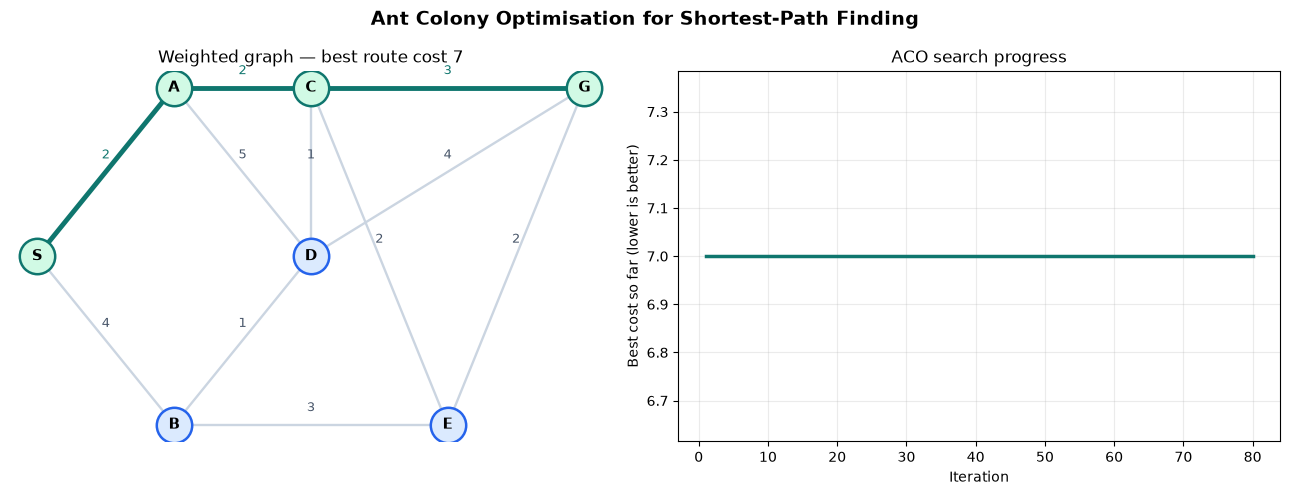

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
layout = {'S':(0,1), 'A':(1,2), 'B':(1,0), 'C':(2,2), 'D':(2,1), 'E':(3,0), 'G':(4,2)}
best_edges = set(zip(best_path[:-1], best_path[1:])) | set((v,u) for u,v in zip(best_path[:-1],best_path[1:]))
for u,v,cost in edges:
    x1,y1=layout[u]; x2,y2=layout[v]
    axes[0].plot([x1,x2],[y1,y2], color='#0f766e' if (u,v) in best_edges else '#cbd5e1', lw=3.5 if (u,v) in best_edges else 1.7, zorder=1)
    axes[0].text((x1+x2)/2,(y1+y2)/2+0.08,str(cost),color='#0f766e' if (u,v) in best_edges else '#475569',fontsize=9,ha='center')
for node,(x,y) in layout.items():
    axes[0].scatter(x,y,s=650,color='#d1fae5' if node in best_path else '#dbeafe',edgecolor='#0f766e' if node in best_path else '#2563eb',linewidth=1.8,zorder=2)
    axes[0].text(x,y,node,ha='center',va='center',fontweight='bold',fontsize=11,zorder=3)
axes[0].set_title(f'Weighted graph — best route cost {best_cost:.0f}'); axes[0].axis('off')
axes[1].plot(range(1, len(best_history)+1), best_history, color='#0f766e', lw=2.5)
axes[1].set_xlabel('Iteration'); axes[1].set_ylabel('Best cost so far (lower is better)')
axes[1].set_title('ACO search progress'); axes[1].grid(alpha=.25)
fig.suptitle('Ant Colony Optimisation for Shortest-Path Finding', fontsize=14, fontweight='bold')
fig.tight_layout(); plt.show()

## 6. Conclusion

ACO found S -> A -> C -> G, with total cost 2 + 2 + 3 = 7. Dijkstra's algorithm confirms that 7 is the exact minimum for this graph. ACO is still a heuristic: this agreement verifies this small example, not every graph. The graph figure uses the same edge list as the code, and the best-cost plot reflects the recorded checkpoints.